
# ETTh1 – Long-Horizon Forecasting Model Comparison

**Course:** ELE680 – Deep Neural Networks  
**Project:** Group 2 – Long-Horizon Forecasting  
**Dataset:** ETTh1 (Electricity Transformer Temperature)

## Research Question

Does increased model complexity improve long-horizon forecasting performance?

## Models

1. Persistence (baseline)
2. DLinear
3. LSTM
4. Transformer (to be added later)

## Experimental Setup

- Input sequence length: 96 hours
- Forecasting horizons: 96, 336, and 720 hours
- Target variable: Oil Temperature (OT)
- Evaluation metrics: MSE and MAE
- Additional comparison: Trainable parameters and training time

## Notebook Objectives

- Combine saved experimental results from all models.
- Compare forecasting accuracy across prediction horizons.
- Calculate improvements relative to the Persistence baseline.
- Analyze the relationship between model complexity and performance.
- Generate figures and tables for the final project report.


In [2]:

# Step 2: Import libraries and locate saved results

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project directories
results_dir = Path("results")
figures_dir = Path("figures")

# Check that the results directory exists
print("Results directory exists:", results_dir.exists())

# List available CSV result files
print("\n===== Available Experimental Results =====")

csv_files = sorted(results_dir.glob("*.csv"))

for file in csv_files:
    print(file.name)

print("\nTotal CSV files found:", len(csv_files))


Results directory exists: True

===== Available Experimental Results =====
DLinear_ETTh1_336h_results.csv
DLinear_ETTh1_720h_results.csv
DLinear_ETTh1_lr0.0001_run2_results.csv
DLinear_ETTh1_results.csv
Forecasting_Model_Comparison.csv
LSTM_336h_simple_results.csv
LSTM_720h_simple_results.csv
LSTM_96h_Validation_Comparison.csv
LSTM_96h_initial_results.csv
LSTM_96h_simple_results.csv
LSTM_All_Horizons_Results.csv
Persistence_All_Horizons.csv

Total CSV files found: 12


In [3]:

# Step 3: Combine final experimental results

# 1. Load Persistence results
persistence = pd.read_csv(
    results_dir / "Persistence_All_Horizons.csv"
)

persistence = persistence.rename(columns={
    "model": "Model",
    "input_len": "Input_Length",
    "pred_len": "Prediction_Length",
    "val_mse": "Validation_MSE",
    "val_mae": "Validation_MAE",
    "test_mse": "Test_MSE",
    "test_mae": "Test_MAE"
})

persistence["Parameters"] = 0

# 2. Load final DLinear results
dlinear_files = [
    "DLinear_ETTh1_lr0.0001_run2_results.csv",
    "DLinear_ETTh1_336h_results.csv",
    "DLinear_ETTh1_720h_results.csv"
]

dlinear_frames = []

for filename in dlinear_files:
    df = pd.read_csv(results_dir / filename)

    df = df.rename(columns={
        "model": "Model",
        "input_len": "Input_Length",
        "pred_len": "Prediction_Length",
        "val_mse": "Validation_MSE",
        "val_mae": "Validation_MAE",
        "test_mse": "Test_MSE",
        "test_mae": "Test_MAE",
        "parameters": "Parameters"
    })

    dlinear_frames.append(df)

dlinear = pd.concat(dlinear_frames, ignore_index=True)

# 3. Load final LSTM results
lstm = pd.read_csv(
    results_dir / "LSTM_All_Horizons_Results.csv"
)

lstm = lstm.rename(columns={
    "Trainable_Parameters": "Parameters"
})

# 4. Combine all models
comparison = pd.concat(
    [persistence, dlinear, lstm],
    ignore_index=True
)

# 5. Select common columns
columns = [
    "Model",
    "Input_Length",
    "Prediction_Length",
    "Validation_MSE",
    "Test_MSE",
    "Test_MAE",
    "Parameters"
]

comparison = comparison[columns]

# 6. Sort by forecasting horizon and model
model_order = {
    "Persistence": 0,
    "DLinear": 1,
    "LSTM": 2
}

comparison["Model_Order"] = comparison["Model"].map(model_order)

comparison = (
    comparison
    .sort_values(["Prediction_Length", "Model_Order"])
    .drop(columns="Model_Order")
    .reset_index(drop=True)
)

# 7. Verify the nine expected experiments
expected_pairs = {
    (model, horizon)
    for model in ["Persistence", "DLinear", "LSTM"]
    for horizon in [96, 336, 720]
}

actual_pairs = set(
    zip(comparison["Model"], comparison["Prediction_Length"])
)

assert len(comparison) == 9, "Expected exactly 9 experiments"
assert actual_pairs == expected_pairs, "Missing or unexpected experiments"
assert comparison[
    ["Validation_MSE", "Test_MSE", "Test_MAE"]
].notna().all().all(), "Missing evaluation metrics"

comparison["Parameters"] = comparison["Parameters"].astype(int)

print("===== Final Model Comparison =====")
display(comparison.round(6))


===== Final Model Comparison =====


,Model,Input_Length,Prediction_Length,Validation_MSE,Test_MSE,Test_MAE,Parameters
0,Persistence,96,96,0.137300,0.069300,0.203300,0
1,DLinear,96,96,0.096491,0.064651,0.187502,18624
2,LSTM,96,96,0.260937,0.501855,0.645748,8416
3,Persistence,96,336,0.185977,0.113274,0.265204,0
4,DLinear,96,336,0.128641,0.095971,0.240374,65184
5,LSTM,96,336,0.283172,0.612728,0.737606,16336
6,Persistence,96,720,0.248023,0.129179,0.283409,0
7,DLinear,96,720,0.156942,0.167763,0.335462,139680
8,LSTM,96,720,0.373152,0.857829,0.876643,29008


In [4]:

# Step 4: Calculate model rankings and improvements

# 1. Get Persistence MSE for each forecasting horizon
baseline_mse = (
    comparison[comparison["Model"] == "Persistence"]
    .set_index("Prediction_Length")["Test_MSE"]
)

# 2. Calculate percentage improvement over Persistence
comparison["MSE_Improvement_%"] = (
    (
        comparison["Prediction_Length"].map(baseline_mse)
        - comparison["Test_MSE"]
    )
    / comparison["Prediction_Length"].map(baseline_mse)
    * 100
)

# 3. Rank models within each forecasting horizon
# Rank 1 = lowest Test MSE
comparison["MSE_Rank"] = (
    comparison.groupby("Prediction_Length")["Test_MSE"]
    .rank(method="min", ascending=True)
    .astype(int)
)

# 4. Display the full comparison
print("===== Model Rankings and Improvements =====")

display(
    comparison[
        [
            "Prediction_Length",
            "Model",
            "Test_MSE",
            "Test_MAE",
            "Parameters",
            "MSE_Improvement_%",
            "MSE_Rank"
        ]
    ].round(4)
)

# 5. Identify the best model for each horizon
best_models = comparison.loc[
    comparison.groupby("Prediction_Length")["Test_MSE"].idxmin()
]

print("\n===== Best Model for Each Horizon =====")

display(
    best_models[
        [
            "Prediction_Length",
            "Model",
            "Test_MSE",
            "Test_MAE",
            "MSE_Improvement_%"
        ]
    ].round(4)
)


===== Model Rankings and Improvements =====


,Prediction_Length,Model,Test_MSE,Test_MAE,Parameters,MSE_Improvement_%,MSE_Rank
0,96,Persistence,0.0693,0.2033,0,0.0000,2
1,96,DLinear,0.0647,0.1875,18624,6.7088,1
2,96,LSTM,0.5019,0.6457,8416,-624.1773,3
3,336,Persistence,0.1133,0.2652,0,0.0000,2
4,336,DLinear,0.0960,0.2404,65184,15.2750,1
5,336,LSTM,0.6127,0.7376,16336,-440.9254,3
6,720,Persistence,0.1292,0.2834,0,0.0000,1
7,720,DLinear,0.1678,0.3355,139680,-29.8683,2
8,720,LSTM,0.8578,0.8766,29008,-564.0602,3



===== Best Model for Each Horizon =====


,Prediction_Length,Model,Test_MSE,Test_MAE,MSE_Improvement_%
1,96,DLinear,0.0647,0.1875,6.7088
4,336,DLinear,0.0960,0.2404,15.2750
6,720,Persistence,0.1292,0.2834,0.0000


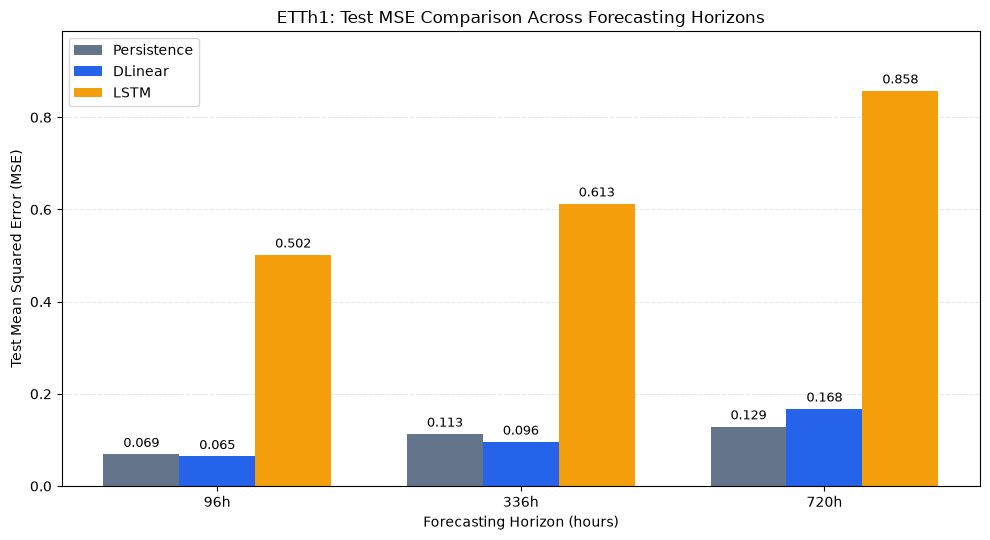

Figure saved to: figures/Model_Comparison_Test_MSE.png


In [5]:

# Step 5: Compare Test MSE across forecasting horizons

horizons = [96, 336, 720]
models = ["Persistence", "DLinear", "LSTM"]

# Arrange results for plotting
mse_table = comparison.pivot(
    index="Prediction_Length",
    columns="Model",
    values="Test_MSE"
).loc[horizons, models]

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(len(horizons))
bar_width = 0.25

colors = {
    "Persistence": "#64748b",
    "DLinear": "#2563eb",
    "LSTM": "#f59e0b"
}

for i, model in enumerate(models):
    bars = ax.bar(
        x + (i - 1) * bar_width,
        mse_table[model],
        width=bar_width,
        label=model,
        color=colors[model]
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels([f"{h}h" for h in horizons])

ax.set_xlabel("Forecasting Horizon (hours)")
ax.set_ylabel("Test Mean Squared Error (MSE)")
ax.set_title("ETTh1: Test MSE Comparison Across Forecasting Horizons")

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(0, mse_table.to_numpy().max() * 1.15)

plt.tight_layout()

# Save high-resolution figure
figures_dir.mkdir(parents=True, exist_ok=True)

figure_path = figures_dir / "Model_Comparison_Test_MSE.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {figure_path}")


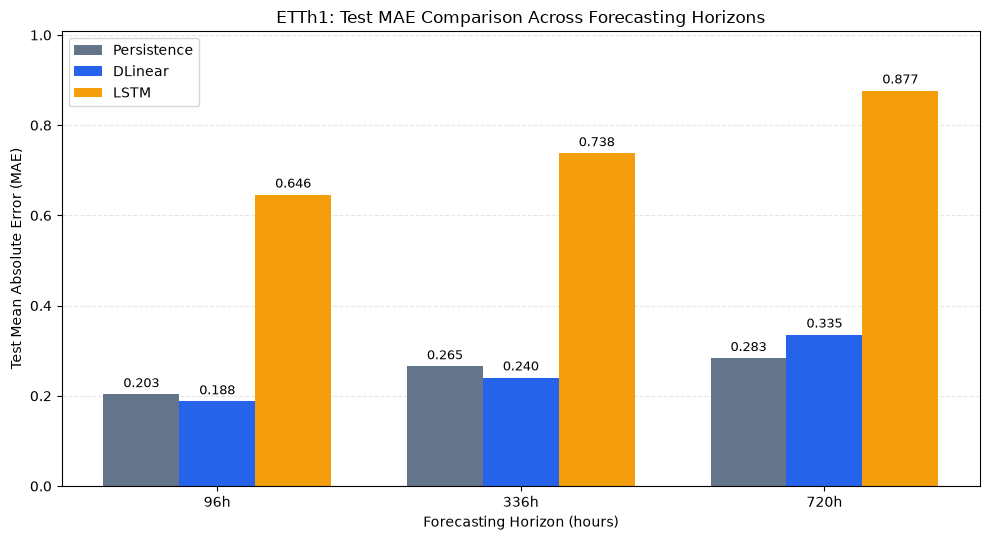

Figure saved to: figures/Model_Comparison_Test_MAE.png


In [6]:

# Step 6: Compare Test MAE across forecasting horizons

# Arrange MAE results for plotting
mae_table = comparison.pivot(
    index="Prediction_Length",
    columns="Model",
    values="Test_MAE"
).loc[horizons, models]

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(len(horizons))
bar_width = 0.25

for i, model in enumerate(models):
    bars = ax.bar(
        x + (i - 1) * bar_width,
        mae_table[model],
        width=bar_width,
        label=model,
        color=colors[model]
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels([f"{h}h" for h in horizons])

ax.set_xlabel("Forecasting Horizon (hours)")
ax.set_ylabel("Test Mean Absolute Error (MAE)")
ax.set_title("ETTh1: Test MAE Comparison Across Forecasting Horizons")

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(0, mae_table.to_numpy().max() * 1.15)

plt.tight_layout()

# Save high-resolution figure
figure_path = figures_dir / "Model_Comparison_Test_MAE.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {figure_path}")


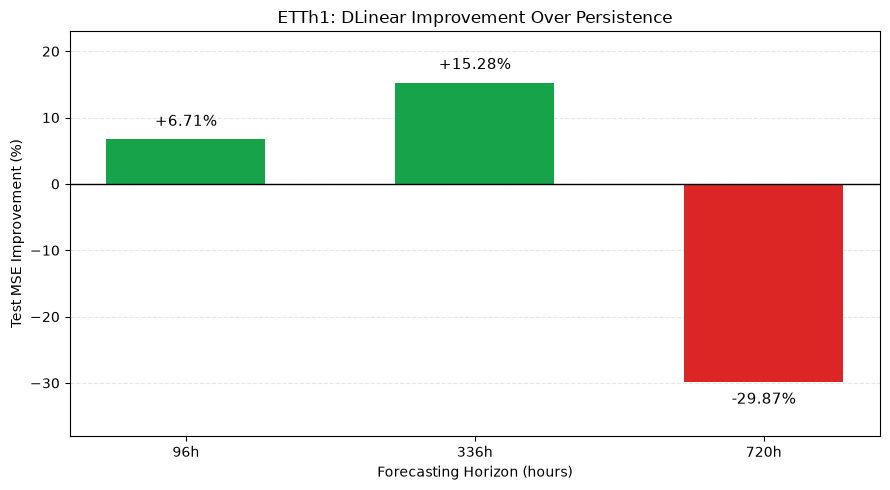

Figure saved to: figures/Model_Comparison_DLinear_Improvement.png


In [7]:

# Step 7: Visualize DLinear improvement over Persistence

# Select DLinear results
dlinear_improvement = comparison[
    comparison["Model"] == "DLinear"
].sort_values("Prediction_Length")

horizons = dlinear_improvement["Prediction_Length"].to_numpy()
improvements = dlinear_improvement["MSE_Improvement_%"].to_numpy()

# Create chart
fig, ax = plt.subplots(figsize=(9, 5))

bar_colors = [
    "#16a34a" if value >= 0 else "#dc2626"
    for value in improvements
]

bars = ax.bar(
    [f"{h}h" for h in horizons],
    improvements,
    color=bar_colors,
    width=0.55
)

# Reference line: no improvement
ax.axhline(0, color="black", linewidth=1)

# Percentage labels
for bar, value in zip(bars, improvements):
    x = bar.get_x() + bar.get_width() / 2
    offset = 1.5 if value >= 0 else -1.5

    ax.text(
        x,
        value + offset,
        f"{value:+.2f}%",
        ha="center",
        va="bottom" if value >= 0 else "top",
        fontsize=11
    )

ax.set_xlabel("Forecasting Horizon (hours)")
ax.set_ylabel("Test MSE Improvement (%)")

ax.set_title(
    "ETTh1: DLinear Improvement Over Persistence"
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(-38, 23)

plt.tight_layout()

# Save figure
figure_path = (
    figures_dir / "Model_Comparison_DLinear_Improvement.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {figure_path}")


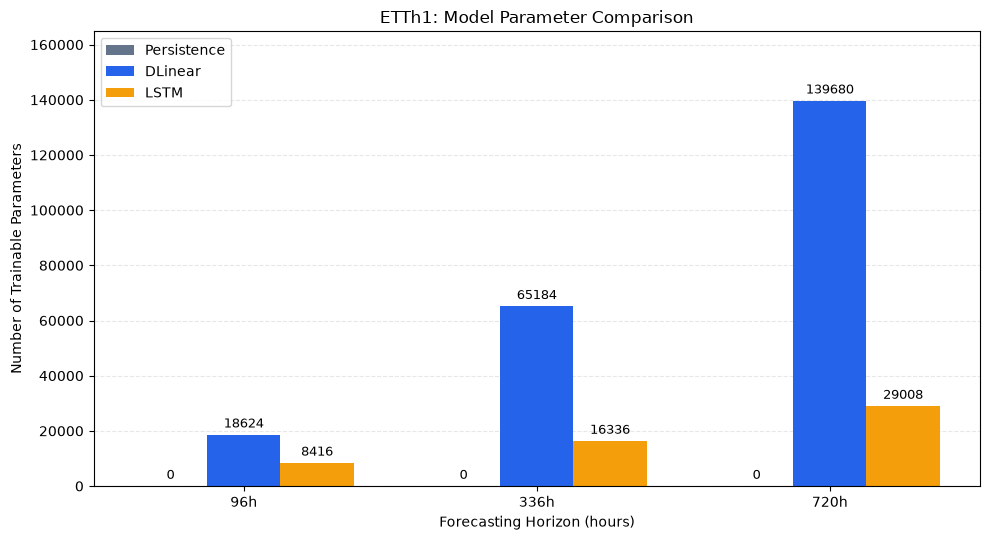

Figure saved to: figures/Model_Comparison_Parameters.png


In [8]:

# Step 8: Compare model complexity using parameter counts

# Prepare parameter counts
parameter_table = comparison.pivot(
    index="Prediction_Length",
    columns="Model",
    values="Parameters"
).loc[[96, 336, 720], ["Persistence", "DLinear", "LSTM"]]

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(3)
bar_width = 0.25

for i, model in enumerate(models):
    bars = ax.bar(
        x + (i - 1) * bar_width,
        parameter_table[model],
        width=bar_width,
        label=model,
        color=colors[model]
    )

    ax.bar_label(
        bars,
        fmt="%.0f",
        padding=3,
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(["96h", "336h", "720h"])

ax.set_xlabel("Forecasting Horizon (hours)")
ax.set_ylabel("Number of Trainable Parameters")
ax.set_title("ETTh1: Model Parameter Comparison")

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(0, parameter_table.to_numpy().max() * 1.18)

plt.tight_layout()

# Save high-resolution figure
figure_path = figures_dir / "Model_Comparison_Parameters.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to: {figure_path}")


In [9]:

# Step 9: Check available training-time measurements

training_files = [
    "DLinear_ETTh1_results.csv",
    "DLinear_ETTh1_lr0.0001_run2_results.csv",
    "DLinear_ETTh1_336h_results.csv",
    "DLinear_ETTh1_720h_results.csv",
    "LSTM_All_Horizons_Results.csv"
]

for filename in training_files:

    df = pd.read_csv(results_dir / filename)

    time_columns = [
        col for col in df.columns
        if "time" in col.lower()
    ]

    print(f"\n===== {filename} =====")

    if time_columns:
        print(df[time_columns].to_string(index=False))
    else:
        print("No training-time column found")



===== DLinear_ETTh1_results.csv =====
 Training_Time_Seconds
                  6.24

===== DLinear_ETTh1_lr0.0001_run2_results.csv =====
No training-time column found

===== DLinear_ETTh1_336h_results.csv =====
No training-time column found

===== DLinear_ETTh1_720h_results.csv =====
No training-time column found

===== LSTM_All_Horizons_Results.csv =====
 Training_Time_Seconds
              8.812514
             11.479456
             11.089589


In [10]:

# Step 10: Save consolidated model comparison results

# Create a separate table for saving
final_comparison = comparison.copy()

# Add available training times
lstm_times = lstm.set_index("Prediction_Length")[
    "Training_Time_Seconds"
]

final_comparison["Training_Time_Seconds"] = np.nan

lstm_mask = final_comparison["Model"] == "LSTM"

final_comparison.loc[
    lstm_mask, "Training_Time_Seconds"
] = final_comparison.loc[
    lstm_mask, "Prediction_Length"
].map(lstm_times)

# Arrange columns for the final results file
final_columns = [
    "Model",
    "Input_Length",
    "Prediction_Length",
    "Validation_MSE",
    "Test_MSE",
    "Test_MAE",
    "Parameters",
    "Training_Time_Seconds",
    "MSE_Improvement_%",
    "MSE_Rank"
]

final_comparison = final_comparison[final_columns]

# Save to a new CSV file
output_path = (
    results_dir / "Final_Model_Comparison_3Models.csv"
)

final_comparison.to_csv(output_path, index=False)

print("===== Final Comparison Table =====")
display(final_comparison.round(4))

print(f"\nSaved successfully to: {output_path}")


===== Final Comparison Table =====


,Model,Input_Length,Prediction_Length,Validation_MSE,Test_MSE,Test_MAE,Parameters,Training_Time_Seconds,MSE_Improvement_%,MSE_Rank
0,Persistence,96,96,0.1373,0.0693,0.2033,0,NaN,0.0000,2
1,DLinear,96,96,0.0965,0.0647,0.1875,18624,NaN,6.7088,1
2,LSTM,96,96,0.2609,0.5019,0.6457,8416,8.8125,-624.1773,3
3,Persistence,96,336,0.1860,0.1133,0.2652,0,NaN,0.0000,2
4,DLinear,96,336,0.1286,0.0960,0.2404,65184,NaN,15.2750,1
5,LSTM,96,336,0.2832,0.6127,0.7376,16336,11.4795,-440.9254,3
6,Persistence,96,720,0.2480,0.1292,0.2834,0,NaN,0.0000,1
7,DLinear,96,720,0.1569,0.1678,0.3355,139680,NaN,-29.8683,2
8,LSTM,96,720,0.3732,0.8578,0.8766,29008,11.0896,-564.0602,3



Saved successfully to: results/Final_Model_Comparison_3Models.csv



## Experimental Findings and Discussion

### 1. Forecasting Accuracy

Three forecasting approaches were evaluated on the ETTh1 dataset:
Persistence, DLinear, and LSTM. All experiments used a 96-hour
input window and forecasting horizons of 96, 336, and 720 hours.

DLinear achieved the lowest test MSE and MAE at the 96-hour
and 336-hour horizons. Compared with Persistence, DLinear
reduced test MSE by approximately 6.71% and 15.28%,
respectively.

At the 720-hour horizon, Persistence achieved the lowest
test MSE (0.1292), outperforming DLinear (0.1678)
and LSTM (0.8578).

### 2. LSTM Performance

The evaluated LSTM configuration produced higher
forecasting errors than both Persistence and DLinear
at all three horizons.

This result suggests that the chosen recurrent architecture
and training configuration were less effective for this
particular forecasting task. It does not imply that
LSTM models are generally unsuitable for time-series
forecasting.

### 3. Model Complexity

Persistence requires no trainable parameters.

DLinear parameter counts increased from 18,624 at
96 hours to 139,680 at 720 hours.

LSTM parameter counts increased from 8,416 to
29,008 across the same horizons.

Despite having more trainable parameters than LSTM,
DLinear achieved lower forecasting errors in all
three experiments.

Parameter count alone does not fully describe
computational complexity or training efficiency.

### 4. Computational Efficiency

LSTM training times ranged from approximately
8.81 to 11.48 seconds.

Training-time measurements were unavailable for
the selected DLinear experiments. Therefore,
a complete training-time comparison cannot yet
be made.

### 5. Limitations

- Results are based on one dataset (ETTh1).
- Only one selected configuration per model and horizon
  is included in the primary comparison.
- The forecasting horizons have different evaluation
  window counts.
- The reported MSE and MAE values are calculated
  on the standardized OT target.
- Transformer results are not yet available.
- The observed differences should not be interpreted
  as universal superiority of one architecture.

### 6. Preliminary Conclusion

The current experiments indicate that increasing
forecasting model complexity does not guarantee
improved long-horizon prediction accuracy.

DLinear performed best at the shorter two horizons,
whereas the simple Persistence baseline achieved
the lowest error at the longest horizon.

A more complete conclusion will be drawn after
incorporating the Transformer experiments.


In [11]:

# Step 12.1: Verify model comparison files

from pathlib import Path

required_files = [
    # Comparison notebook
    "07_ETTh1_Model_Comparison.ipynb",

    # Final comparison results
    "results/Final_Model_Comparison_3Models.csv",

    # Comparison figures
    "figures/Model_Comparison_Test_MSE.png",
    "figures/Model_Comparison_Test_MAE.png",
    "figures/Model_Comparison_DLinear_Improvement.png",
    "figures/Model_Comparison_Parameters.png"
]

print("===== Model Comparison File Verification =====")

all_files_exist = True

for filename in required_files:
    file_path = Path(filename)

    if file_path.is_file():
        size_kb = file_path.stat().st_size / 1024
        print(f"OK: {filename} ({size_kb:.2f} KB)")
    else:
        print(f"MISSING: {filename}")
        all_files_exist = False

print("\n===== Verification Result =====")

if all_files_exist:
    print("SUCCESS: All 6 comparison files exist.")
else:
    print("WARNING: Some files are missing.")


===== Model Comparison File Verification =====
OK: 07_ETTh1_Model_Comparison.ipynb (221.45 KB)
OK: results/Final_Model_Comparison_3Models.csv (0.96 KB)
OK: figures/Model_Comparison_Test_MSE.png (126.09 KB)
OK: figures/Model_Comparison_Test_MAE.png (127.52 KB)
OK: figures/Model_Comparison_DLinear_Improvement.png (93.72 KB)
OK: figures/Model_Comparison_Parameters.png (127.66 KB)

===== Verification Result =====
SUCCESS: All 6 comparison files exist.
